# Do pedido à saída da rede: meu estudo de forward pass

Meu objetivo é acompanhar o caminho de um pedido dentro de uma rede pequena: combinação linear, ativação, saída, limiar e erro. Nesta atividade, os pesos permanecem sem treinamento.

**Ponto de partida:** [atividade_tensorflow.ipynb](https://github.com/biaag10/machine_learning_projects/tree/develop/deep_learning/notebooks/atividade_tensorflow.ipynb), do projeto de referência disponibilizado para estudo. Esta versão reorganiza a atividade, explicita decisões e deixa a interpretação dos resultados para a execução neste projeto.

**Como usar:** kernel da `.venv` de `deep_learning`; executar de cima para baixo. As saídas antigas foram removidas. Os resultados abaixo precisam ser gerados nesta execução.


In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
try:
    from IPython.display import display
except ImportError:
    display = print

SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18,
    "axes.prop_cycle": plt.cycler(color=["#0f766e", "#d97706", "#6366f1", "#be185d"]),
})
current = Path.cwd().resolve()
ROOT = next((p for p in [current, *current.parents]
             if (p / "module_deep_learning").is_dir()
             and (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Abra este notebook em deep_learning/notebooks e use a .venv do projeto.")
sys.path.insert(0, str(ROOT))
print("TensorFlow:", tf.__version__)
print("Python:", sys.executable)


def batches(X, y=None, batch_size=256, training=False):
    values = np.asarray(X, dtype="float32")
    tensors = values if y is None else (values, np.asarray(y))
    ds = tf.data.Dataset.from_tensor_slices(tensors)
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    return ds.batch(batch_size).with_options(options).prefetch(1)


TensorFlow: 2.21.0
Python: c:\Users\Rafael Athaliba\Projetos Git\Machine_Learning\Machine_Learning_entrega\deep_learning\.venv\Scripts\python.exe


## 1. Um exemplo pequeno para enxergar as contas

Os seis pedidos abaixo são **hipotéticos**. Distância, itens e frete já estão em escala normalizada para facilitar o exercício; não são registros reais da Olist. Uma linha representa um pedido, e uma coluna representa uma característica. O alvo 1 indica atraso no exemplo.


In [2]:
X = tf.constant([
    [0.20, 0.10, 0.30], [0.80, 0.70, 0.90],
    [0.30, 0.20, 0.40], [0.90, 0.80, 0.70],
    [0.15, 0.30, 0.20], [0.75, 0.60, 0.85],
], dtype=tf.float32)
y = tf.constant([[0], [1], [0], [1], [0], [1]], dtype=tf.float32)
table = pd.DataFrame(X.numpy(), columns=["distancia", "itens", "frete"])
table["atrasou"] = y.numpy().ravel().astype(int)
display(table)


,distancia,itens,frete,atrasou
0,0.20,0.1,0.30,0
1,0.80,0.7,0.90,1
2,0.30,0.2,0.40,0
3,0.90,0.8,0.70,1
4,0.15,0.3,0.20,0
5,0.75,0.6,0.85,1


## 2. O que um neurônio calcula?

Primeiro ocorre a combinação $z = x_1w_1 + x_2w_2 + x_3w_3 + b$. Esse valor ainda não é uma probabilidade. Vou usar pesos fixos escolhidos para o exercício e comparar duas ativações: ReLU e sigmoid.


,z,relu(z),sigmoid(z)
0,0.12,0.12,0.529964
1,0.60,0.60,0.645656
2,0.20,0.20,0.549834
3,0.56,0.56,0.636453
4,0.01,0.01,0.502500
5,0.57,0.57,0.638763


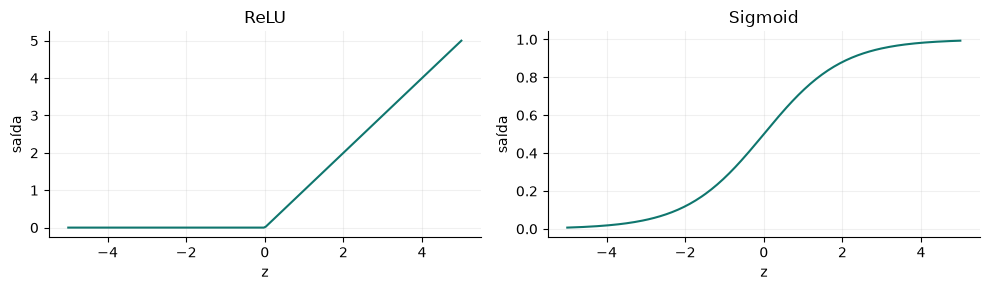

In [3]:
weights = tf.constant([[0.6], [-0.2], [0.4]], dtype=tf.float32)
bias = tf.constant(-0.1, dtype=tf.float32)
z = X @ weights + bias
display(pd.DataFrame({
    "z": z.numpy().ravel(),
    "relu(z)": tf.nn.relu(z).numpy().ravel(),
    "sigmoid(z)": tf.sigmoid(z).numpy().ravel(),
}))
axis = np.linspace(-5, 5, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(axis, np.maximum(axis, 0)); axes[0].set(title="ReLU", xlabel="z", ylabel="saída")
axes[1].plot(axis, tf.sigmoid(axis).numpy()); axes[1].set(title="Sigmoid", xlabel="z", ylabel="saída")
fig.tight_layout(); plt.show()


## 3. Montando a arquitetura 3 → 4 → 1

A camada oculta tem $3 \times 4 + 4 = 16$ parâmetros; a saída tem $4 \times 1 + 1 = 5$. Portanto, são **21 parâmetros da rede**. Como não há treino nem compilação aqui, não misturo essa contagem com variáveis de um otimizador.


In [4]:
keras.utils.set_random_seed(SEED)
model = keras.Sequential([
    layers.Input(shape=(3,)),
    layers.Dense(4, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
], name="primeiro_forward_pass")
model.summary()
assert model.count_params() == 21
initial_weights = [value.copy() for value in model.get_weights()]
probability = model(X, training=False).numpy().ravel()


Model: "primeiro_forward_pass"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21 (84.00 B)

 Trainable params: 21 (84.00 B)

 Non-trainable params: 0 (0.00 B)

## 4. Um escore não é uma decisão

A sigmoid retorna um número entre 0 e 1. A classe depende de um limiar. Como a rede ainda não aprendeu com dados, não interpreto essa saída como uma estimativa confiável de atraso. Vou observar como a classe muda com limiares diferentes.


In [5]:
comparison = pd.DataFrame({"real": y.numpy().ravel().astype(int), "saida_sigmoid": probability})
for threshold in (0.3, 0.5, 0.7):
    comparison[f"classe_limiar_{threshold}"] = (probability >= threshold).astype(int)
display(comparison)


,real,saida_sigmoid,classe_limiar_0.3,classe_limiar_0.5,classe_limiar_0.7
0,0,0.526190,1,1,0
1,1,0.519173,1,1,0
2,0,0.525021,1,1,0
3,1,0.519212,1,1,0
4,0,0.508294,1,1,0
5,1,0.534196,1,1,0


## 5. Medindo o erro antes de aprender

A Binary Cross-Entropy usa o escore, não a classe depois do limiar:

$$L = -[y\ln(\hat y) + (1-y)\ln(1-\hat y)]$$

Para um exemplo com alvo 1, compare as previsões 0,95, 0,60 e 0,05. O erro cresce quando a rede atribui pouca probabilidade à classe verdadeira.


In [6]:
loss_fn = keras.losses.BinaryCrossentropy()
examples = []
for score in (0.95, 0.60, 0.05):
    examples.append({"alvo": 1, "escore": score,
                     "BCE": float(loss_fn([[1.0]], [[score]]).numpy())})
display(pd.DataFrame(examples))
print("BCE da rede sem treino:", float(loss_fn(y, probability.reshape(-1, 1)).numpy()))
for before, after in zip(initial_weights, model.get_weights()):
    np.testing.assert_array_equal(before, after)
print("Conferência: os pesos não foram alterados nesta atividade.")


,alvo,escore,BCE
0,1,0.95,0.051293
1,1,0.60,0.510826
2,1,0.05,2.995732


BCE da rede sem treino: 0.6898769736289978
Conferência: os pesos não foram alterados nesta atividade.


## Minhas observações após executar

- O que aconteceu com a classe quando alterei apenas o limiar?
- Por que uma rede sem treino pode produzir números diferentes para pedidos diferentes?
- O que ainda falta para diminuir a loss por aprendizado?

Antes de marcar como concluído, quero conseguir explicar: pesos e bias, não linearidade, 21 parâmetros, forward pass e a diferença entre escore, classe e loss. O próximo notebook estuda a atualização dos pesos.
